In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#Loading the CSV files
train_transaction = pd.read_csv(r"C:\Users\cricb\Desktop\Course Notes\WiM - DRP ML\train_transaction.csv.zip")
train_identity = pd.read_csv(r"C:\Users\cricb\Desktop\Course Notes\WiM - DRP ML\train_identity.csv.zip")
#Merging on Transaction ID
df = pd.merge(train_transaction, train_identity, on = "TransactionID", how = "left")

count    590540.000000
mean          0.346071
std           0.052145
min           0.307676
25%           0.316222
50%           0.325802
75%           0.355789
max           0.778983
Name: anomaly_score1, dtype: float64


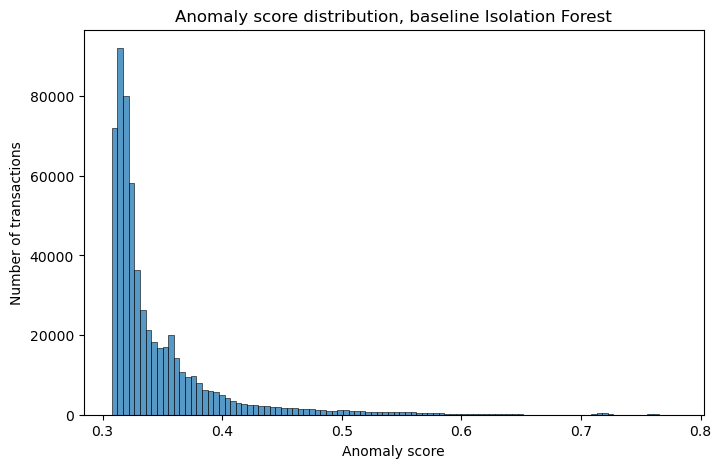

        TransactionID  anomaly_score1  TransactionAmt
79711         3066711        0.778983          1000.0
539947        3526947        0.763541           106.0
539948        3526948        0.763541           106.0
539950        3526950        0.763541           106.0
539953        3526953        0.763541           106.0
539954        3526954        0.763541           106.0
540044        3527044        0.763541           106.0
540050        3527050        0.763541           106.0
540075        3527075        0.763541           106.0
540083        3527083        0.763541           106.0
Overall fraud rate: 0.03499000914417313
Frauds in top 10: 0 / 10
Top 10: 0 frauds (0.0%)
Top 100: 0 frauds (0.0%)
Top 1000: 0 frauds (0.0%)
baseline  flagged: 16468 | frauds: 4250 | precision: 0.2581 | recall: 0.2057


In [21]:
#Baseline
cols = df.columns
labels = df['isFraud']
excluded_columns = ['TransactionID', 'isFraud', 'ProductCD', 'card4', 'card6', 
                    'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 
                    'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 
                    'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 
                    'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'V254', 
                    'DeviceType', 'DeviceInfo']

it_one_features = list(set(cols) - set(excluded_columns))
x_1 = df[it_one_features]

#Filling missing values with each column's median
x_1 = x_1.fillna(x_1.median())

#Fitting the baseline isolation forrest
from sklearn.ensemble import IsolationForest
iso_forest = IsolationForest(contamination='auto', random_state=42)
iso_forest.fit(x_1)

#Finding anomally scores for iteration one
df['anomaly_score1'] = -1 * iso_forest.score_samples(x_1)
print(df['anomaly_score1'].describe())

#Distribution of anomaly scores
plt.figure(figsize=(8, 5))
sns.histplot(df['anomaly_score1'], bins=100)
plt.xlabel('Anomaly score')
plt.ylabel('Number of transactions')
plt.title('Anomaly score distribution, baseline Isolation Forest')
plt.show()

#Top 10 most anomalous transactions
top10 = df.nlargest(10, 'anomaly_score1')
print(top10[['TransactionID', 'anomaly_score1', 'TransactionAmt']])

#Peeking at the withheld labels
print("Overall fraud rate:", labels.mean())
print("Frauds in top 10:", labels[top10.index].sum(), "/ 10")
for k in [10, 100, 1000]:
    topk = df.nlargest(k, 'anomaly_score1').index
    print(f"Top {k}: {labels[topk].sum()} frauds ({labels[topk].mean():.1%})")

#Baseline performance
flagged_baseline = iso_forest.predict(x_1) == -1
print("baseline  flagged:", flagged_baseline.sum(), "| frauds:", labels[flagged_baseline].sum(),
      "| precision:", round(labels[flagged_baseline].mean(), 4),
      "| recall:", round(labels[flagged_baseline].sum() / labels.sum(), 4))
base_scores = df['anomaly_score1'].values
base_top1000 = set(df.nlargest(1000, 'anomaly_score1').index)

In [19]:
#Changing the contamination
#contamination = 0.01
iso_c01 = IsolationForest(contamination=0.01, random_state=42)
iso_c01.fit(x_1)
flagged_c01 = iso_c01.predict(x_1) == -1
print("0.01  flagged:", flagged_c01.sum(), "| frauds:", labels[flagged_c01].sum(),
      "| precision:", round(labels[flagged_c01].mean(), 4),
      "| recall:", round(labels[flagged_c01].sum() / labels.sum(), 4))

#contamination = 0.02
iso_c02 = IsolationForest(contamination=0.02, random_state=42)
iso_c02.fit(x_1)
flagged_c02 = iso_c02.predict(x_1) == -1
print("0.02  flagged:", flagged_c02.sum(), "| frauds:", labels[flagged_c02].sum(),
      "| precision:", round(labels[flagged_c02].mean(), 4),
      "| recall:", round(labels[flagged_c02].sum() / labels.sum(), 4))

#contamination = 0.035 - close to the real fraud rate!
iso_c035 = IsolationForest(contamination=0.035, random_state=42)
iso_c035.fit(x_1)
flagged_c035 = iso_c035.predict(x_1) == -1
print("0.035 flagged:", flagged_c035.sum(), "| frauds:", labels[flagged_c035].sum(),
      "| precision:", round(labels[flagged_c035].mean(), 4),
      "| recall:", round(labels[flagged_c035].sum() / labels.sum(), 4))

#contamination = 0.05
iso_c05 = IsolationForest(contamination=0.05, random_state=42)
iso_c05.fit(x_1)
flagged_c05 = iso_c05.predict(x_1) == -1
print("0.05  flagged:", flagged_c05.sum(), "| frauds:", labels[flagged_c05].sum(),
      "| precision:", round(labels[flagged_c05].mean(), 4),
      "| recall:", round(labels[flagged_c05].sum() / labels.sum(), 4))

#contamination = 0.1
iso_c10 = IsolationForest(contamination=0.1, random_state=42)
iso_c10.fit(x_1)
flagged_c10 = iso_c10.predict(x_1) == -1
print("0.10  flagged:", flagged_c10.sum(), "| frauds:", labels[flagged_c10].sum(),
      "| precision:", round(labels[flagged_c10].mean(), 4),
      "| recall:", round(labels[flagged_c10].sum() / labels.sum(), 4))

0.01  flagged: 5905 | frauds: 1516 | precision: 0.2567 | recall: 0.0734
0.02  flagged: 11811 | frauds: 3160 | precision: 0.2675 | recall: 0.1529
0.035 flagged: 20669 | frauds: 4959 | precision: 0.2399 | recall: 0.24
0.05  flagged: 29527 | frauds: 6305 | precision: 0.2135 | recall: 0.3051
0.10  flagged: 59054 | frauds: 9008 | precision: 0.1525 | recall: 0.4359


In [26]:
#Changing the number of estimators
from scipy.stats import spearmanr

#n_estimators = 50
iso_t50 = IsolationForest(n_estimators=50, random_state=42, n_jobs=-1)
iso_t50.fit(x_1)
scores_t50 = -1 * iso_t50.score_samples(x_1)

#n_estimators = 200
iso_t200 = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)
iso_t200.fit(x_1)
scores_t200 = -1 * iso_t200.score_samples(x_1)

#n_estimators = 500
iso_t500 = IsolationForest(n_estimators=500, random_state=42, n_jobs=-1)
iso_t500.fit(x_1)
scores_t500 = -1 * iso_t500.score_samples(x_1)

#Seeing if the rankings stabilize (the baseline has 100 trees, as per default)
print("50 vs 100 trees: ", round(spearmanr(scores_t50, base_scores)[0], 4))
print("100 vs 200 trees:", round(spearmanr(base_scores, scores_t200)[0], 4))
print("200 vs 500 trees:", round(spearmanr(scores_t200, scores_t500)[0], 4))

#Label peek: frauds in the top 1000 for each estimators setting
for name, sc in [("50", scores_t50), ("100", base_scores), ("200", scores_t200), ("500", scores_t500)]:
    top1000 = pd.Series(sc, index=df.index).nlargest(1000).index
    print(name, "trees | frauds in top 1000:", labels[top1000].sum())

50 vs 100 trees:  0.9702
100 vs 200 trees: 0.9875
200 vs 500 trees: 0.9911
50 trees | frauds in top 1000: 16
100 trees | frauds in top 1000: 0
200 trees | frauds in top 1000: 0
500 trees | frauds in top 1000: 0


In [28]:
#Changing the number of samples
#max_samples = 128
iso_s128 = IsolationForest(max_samples=128, random_state=42, n_jobs=-1)
iso_s128.fit(x_1)
scores_s128 = -1 * iso_s128.score_samples(x_1)

#max_samples = 512
iso_s512 = IsolationForest(max_samples=512, random_state=42, n_jobs=-1)
iso_s512.fit(x_1)
scores_s512 = -1 * iso_s512.score_samples(x_1)

#max_samples = 10000
iso_s10k = IsolationForest(max_samples=10000, random_state=42, n_jobs=-1)
iso_s10k.fit(x_1)
scores_s10k = -1 * iso_s10k.score_samples(x_1)

#max_samples = full training set (optional, can be very slow, run last)
iso_sfull = IsolationForest(max_samples=len(x_1), random_state=42, n_jobs=-1)
iso_sfull.fit(x_1)
scores_sfull = -1 * iso_sfull.score_samples(x_1)

#Does the ranking change vs baseline? (1.0 = identical ranking)
print("Sample number vs baseline (256)")
print("128:   ", round(spearmanr(scores_s128, base_scores)[0], 4))
print("512:   ", round(spearmanr(scores_s512, base_scores)[0], 4))
print("10000: ", round(spearmanr(scores_s10k, base_scores)[0], 4))
print("full:  ", round(spearmanr(scores_sfull, base_scores)[0], 4))

#Label peek: frauds in the top 1000 for each setting
print("\nFrauds in top 1000")
for name, sc in [("128", scores_s128), ("256 (base)", base_scores), ("512", scores_s512),
                 ("10000", scores_s10k), ("full", scores_sfull)]:
    top1000 = pd.Series(sc, index=df.index).nlargest(1000).index
    print(name, "|", labels[top1000].sum())

Sample number vs baseline (256)
128:    0.9712
512:    0.9756
10000:  0.9308
full:   0.8815

Frauds in top 1000
128 | 0
256 (base) | 0
512 | 0
10000 | 19
full | 21
